# **Overfitting: más semillas con el muestreo kNN de AE 2**


---

## **1. Configuración e imports**


In [ ]:
%pip install "torchmetrics[image]"
%pip install opencv-python
%pip install pandas
%pip install matplotlib
%pip install tensorflow
%pip install torch
%pip install scikit-learn

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.
Defaulting to user installation because normal site-packages is not writeable
  Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl.metadata (6.6 kB)
Using cached numpy-2.5.4-cp312-cp312-macosx_14_0_arm64.whl (5.5 MB)
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.4
    Uninstalling numpy-1.26.4:
      Successfully uninstalled numpy-1.26.4
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
tensorflow 2.16.2 requires numpy<2.0.0,>=1.26.0; python_version >= "3.12", but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires numpy<2.0,>=1.18.5, but you have numpy 2.5.4 which is incompatible.
gensim 4.3.3 requires scipy<1.14.0,>=1.7.0, but you have scipy 1.15.3 which is incompatible.

In [ ]:
import os
import json

import cv2
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras

import torch
from torchmetrics.image.fid import FrechetInceptionDistance

from sklearn.neighbors import NearestNeighbors

In [ ]:
SEED = 1234                      
IMG_SIZE = 64
TOTAL_IMAGES = 30000            
DATASET_DIR = "data/images"
VAL_FRACTION = 0.10               

N_SAMPLES = 200                   
SAMPLE_SEED = 1234                

FID_NUM_IMAGES_SUBMISSION = 200  
FID_BATCH_SIZE = 64


NOTEBOOK_NAME = "overfitting"
MODEL_NAME = "ae_complex2"        
LATENT_DIM = 256
BATCH_SIZE = 128
KNN_K = 10
OVERFIT_SEEDS = (101, 202, 303)   

# Rutas de los archivos
CHECKPOINT_DIR = "checkpoints"
RESULTS_DIR = "results"
SUBMISSIONS_DIR = "submissions"
AE_PATH = f"{CHECKPOINT_DIR}/{MODEL_NAME}.keras"
ENCODER_PATH = f"{CHECKPOINT_DIR}/encoder_{MODEL_NAME.replace('ae_', '')}.keras"
DECODER_PATH = f"{CHECKPOINT_DIR}/decoder_{MODEL_NAME.replace('ae_', '')}.keras"
METRICS_PATH = f"{RESULTS_DIR}/{NOTEBOOK_NAME}_metrics.json"

---

## **2. Carga de datos y split**


In [4]:
images = np.empty((TOTAL_IMAGES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)

In [5]:
loaded_count = 0

for i in range(TOTAL_IMAGES):
    filename = f"{i}.jpg"
    filepath = os.path.join(DATASET_DIR, filename)
    
    img = cv2.imread(filepath, cv2.IMREAD_GRAYSCALE)
    
    if img is None:
        raise FileNotFoundError(f"Error para cargar la imagen: {filepath}")
    
    if img.shape != (IMG_SIZE, IMG_SIZE):
        img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
        
    images[i] = img
    loaded_count += 1

print(f"Total cargado: {loaded_count} imágenes")

Total cargado: 30000 imágenes


In [6]:
print(f"Forma del tensor: {images.shape}")          # Esperado: (30000, 64, 64)
print(f"Tipo de dato:     {images.dtype}")          # Esperado: uint8
print(f"Valor mínimo:     {images.min()}")          # Esperado: 0 o cercano 
print(f"Valor máximo:     {images.max()}")          # Esperado: 255 o cercano 

Forma del tensor: (30000, 64, 64)
Tipo de dato:     uint8
Valor mínimo:     0
Valor máximo:     255


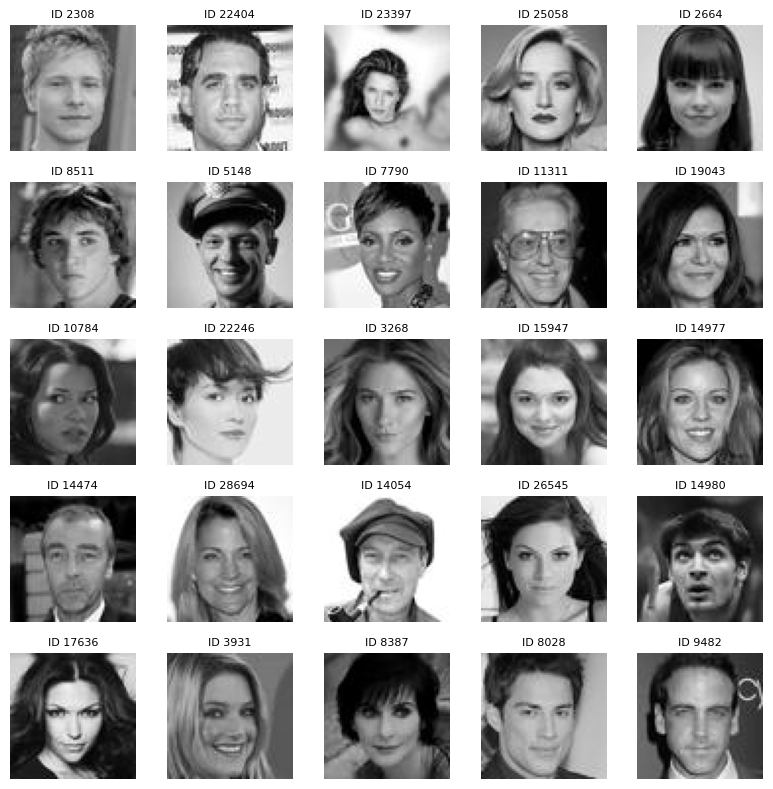

In [7]:
fig, axes = plt.subplots(5, 5, figsize=(8, 8))

np.random.seed(42)
sample_indices = np.random.choice(TOTAL_IMAGES, size=25, replace=False)

for ax, idx in zip(axes.flat, sample_indices):
    ax.imshow(images[idx], cmap="gray", vmin=0, vmax=255)
    ax.axis("off")
    ax.set_title(f"ID {idx}", fontsize=8)

plt.tight_layout()
plt.show()

In [8]:
np.random.seed(SEED)
tf.random.set_seed(SEED)

In [ ]:
x_data = images.astype("float32") / 255.0
x_data = np.expand_dims(x_data, axis=-1) 

val_size = int(VAL_FRACTION * len(x_data))

indices = np.random.permutation(len(x_data))
train_idx, val_idx = indices[val_size:], indices[:val_size]

x_train = x_data[train_idx]
x_val = x_data[val_idx]

print(f"Conjunto de entrenamiento: {x_train.shape}")
print(f"Conjunto de validación:    {x_val.shape}")

Conjunto de entrenamiento: (27000, 64, 64, 1)
Conjunto de validación:    (3000, 64, 64, 1)


---

## **3. Carga del modelo**


In [ ]:
# Carga de encoder y decoder de AE_complex2 y codificación de x_train
missing = [p for p in (ENCODER_PATH, DECODER_PATH) if not os.path.exists(p)]
if missing:
    raise FileNotFoundError(f"Modelos de AE_complex2 no encontrados: {missing}")

encoder_ae = keras.models.load_model(ENCODER_PATH, compile=False)
decoder_ae = keras.models.load_model(DECODER_PATH, compile=False)

z_train = encoder_ae.predict(x_train, batch_size=BATCH_SIZE, verbose=0)
print(f"Modelos cargados de {MODEL_NAME} | z_train: {z_train.shape}")

Modelos cargados de ae_complex2 | z_train: (27000, 256)


---

## **4. FID**


In [ ]:
device = "cpu"

def prepare_images_for_fid(images):
    images = np.asarray(images)

    if images.dtype != np.uint8:
        images = np.clip(images, 0.0, 1.0)
        images = (images * 255.0).round().astype(np.uint8)

    if images.ndim == 3:
        images = images[..., np.newaxis]

    images = np.repeat(images, 3, axis=-1)
    images = np.transpose(images, (0, 3, 1, 2))
    return torch.from_numpy(images)


def calculate_fid(generated_images, real_images, batch_size=FID_BATCH_SIZE):
    fid = FrechetInceptionDistance(feature=2048, normalize=False).to(device)
    real_images = prepare_images_for_fid(real_images)
    generated_images = prepare_images_for_fid(generated_images)

    with torch.inference_mode():
        for start in range(0, len(real_images), batch_size):
            fid.update(real_images[start:start + batch_size].to(device), real=True)
        for start in range(0, len(generated_images), batch_size):
            fid.update(generated_images[start:start + batch_size].to(device), real=False)
        return fid.compute().item()


def decode(z):
    return decoder_ae.predict(np.asarray(z, dtype=np.float32), batch_size=FID_BATCH_SIZE, verbose=0)

---

## **5. Muestreo kNN y submissions por semilla**

In [ ]:
z_fit = z_train.astype(np.float64)

knn = NearestNeighbors(n_neighbors=KNN_K).fit(z_fit)
knn_idx = knn.kneighbors(z_fit, return_distance=False)   


def sample_knn_barycentric(n, rng):
    anchor = rng.integers(len(z_train), size=n)
    w = rng.dirichlet(np.ones(KNN_K), size=n)
    return np.einsum("nk,nkd->nd", w, z_fit[knn_idx[anchor]]).astype(np.float32)


def generate_uint8(seed):
    z = sample_knn_barycentric(N_SAMPLES, np.random.default_rng(seed))
    generated_float = decode(z)
    assert generated_float.shape == (N_SAMPLES, IMG_SIZE, IMG_SIZE, 1)
    assert np.isfinite(generated_float).all()
    assert generated_float.min() >= 0.0 and generated_float.max() <= 1.0
    return np.squeeze(np.clip(np.round(generated_float * 255.0), 0, 255).astype(np.uint8), axis=-1)


print(f"kNN: índices de vecinos {knn_idx.shape}")

kNN: índices de vecinos (27000, 10)


In [ ]:
x_ref = x_val[:FID_NUM_IMAGES_SUBMISSION]
images_by_seed = {SAMPLE_SEED: generate_uint8(SAMPLE_SEED)}
fid_by_seed = {SAMPLE_SEED: calculate_fid(images_by_seed[SAMPLE_SEED], x_ref)}
print(f"Referencia (semilla {SAMPLE_SEED}, la de AE_complex2): FID local (N=200) = {fid_by_seed[SAMPLE_SEED]:.4f}")

ref_csv = f"{SUBMISSIONS_DIR}/submission_{MODEL_NAME}_top1_knn_baricentrico_k_10.csv"
if os.path.exists(ref_csv):
    back = pd.read_csv(ref_csv).iloc[:, 1:].values.astype(np.uint8).reshape(N_SAMPLES, IMG_SIZE, IMG_SIZE)
    print(f"Reproduce {ref_csv}: {np.array_equal(back, images_by_seed[SAMPLE_SEED])}")
else:
    print(f"No se encontró {ref_csv}: se omite la comprobación.")

Referencia (semilla 1234, la de AE_complex2): FID local (N=200) = 92.7883
Reproduce submissions/submission_ae_complex2_top1_knn_baricentrico_k_10.csv: True


In [ ]:
def save_submission(generated_imgs_uint8, path):
    flat_pixels = generated_imgs_uint8.reshape(N_SAMPLES, IMG_SIZE * IMG_SIZE)
    df_submission = pd.DataFrame(
        flat_pixels,
        columns=[str(i) for i in range(IMG_SIZE * IMG_SIZE)]
    )
    df_submission.insert(0, "ID", range(1, N_SAMPLES + 1))

    assert df_submission.shape == (N_SAMPLES, 1 + IMG_SIZE * IMG_SIZE)
    assert df_submission.isnull().sum().sum() == 0
    assert df_submission.iloc[:, 1:].values.min() >= 0
    assert df_submission.iloc[:, 1:].values.max() <= 255
    assert list(df_submission.columns[:2]) == ["ID", "0"]

    os.makedirs(SUBMISSIONS_DIR, exist_ok=True)
    df_submission.to_csv(path, index=False)
    return df_submission


submission_paths = {}
for seed in OVERFIT_SEEDS:
    generated_imgs = generate_uint8(seed)
    images_by_seed[seed] = generated_imgs

    path = f"{SUBMISSIONS_DIR}/submission_{NOTEBOOK_NAME}_knn_seed{seed}.csv"
    df_sub = save_submission(generated_imgs, path)
    submission_paths[seed] = path

    df_back = pd.read_csv(path)
    imgs_back = df_back.iloc[:, 1:].values.astype(np.uint8).reshape(N_SAMPLES, IMG_SIZE, IMG_SIZE)
    assert np.array_equal(imgs_back, generated_imgs), "El CSV no coincide con las imágenes en memoria."
    fid_by_seed[seed] = calculate_fid(imgs_back, x_ref)
    print(f"semilla {seed}: '{path}' | forma {df_sub.shape} | FID local (N=200) = {fid_by_seed[seed]:.4f}")

semilla 101: 'submissions/submission_overfitting_knn_seed101.csv' | forma (200, 4097) | FID local (N=200) = 94.0310
semilla 202: 'submissions/submission_overfitting_knn_seed202.csv' | forma (200, 4097) | FID local (N=200) = 92.3695
semilla 303: 'submissions/submission_overfitting_knn_seed303.csv' | forma (200, 4097) | FID local (N=200) = 90.8330


In [ ]:
summary = pd.DataFrame(
    [{"seed": s, "fid_200": fid_by_seed[s], "es_referencia": s == SAMPLE_SEED} for s in fid_by_seed]
).sort_values("fid_200").reset_index(drop=True)
print(summary.round(4).to_string(index=False))

new_fids = [fid_by_seed[s] for s in OVERFIT_SEEDS]
print(f"\nSemillas nuevas: media = {np.mean(new_fids):.4f} | mín = {np.min(new_fids):.4f} | máx = {np.max(new_fids):.4f}")
print(f"Referencia (semilla {SAMPLE_SEED}): {fid_by_seed[SAMPLE_SEED]:.4f}")

os.makedirs(RESULTS_DIR, exist_ok=True)
metrics = {
    "model": MODEL_NAME,
    "sampling_method": f"kNN baricéntrico (K={KNN_K})",
    "reference_seed": SAMPLE_SEED,
    "fid_200_by_seed": {str(s): float(v) for s, v in fid_by_seed.items()},
    "submissions": {str(s): p for s, p in submission_paths.items()},
}
with open(METRICS_PATH, "w") as f:
    json.dump(metrics, f, indent=2)
print(f"Métricas guardadas en {METRICS_PATH}")

 seed  fid_200  es_referencia
  303  90.8330          False
  202  92.3695          False
 1234  92.7883           True
  101  94.0310          False

Semillas nuevas: media = 92.4111 | mín = 90.8330 | máx = 94.0310
Referencia (semilla 1234): 92.7883
Métricas guardadas en results/overfitting_metrics.json


---

## **6. Muestras generadas**

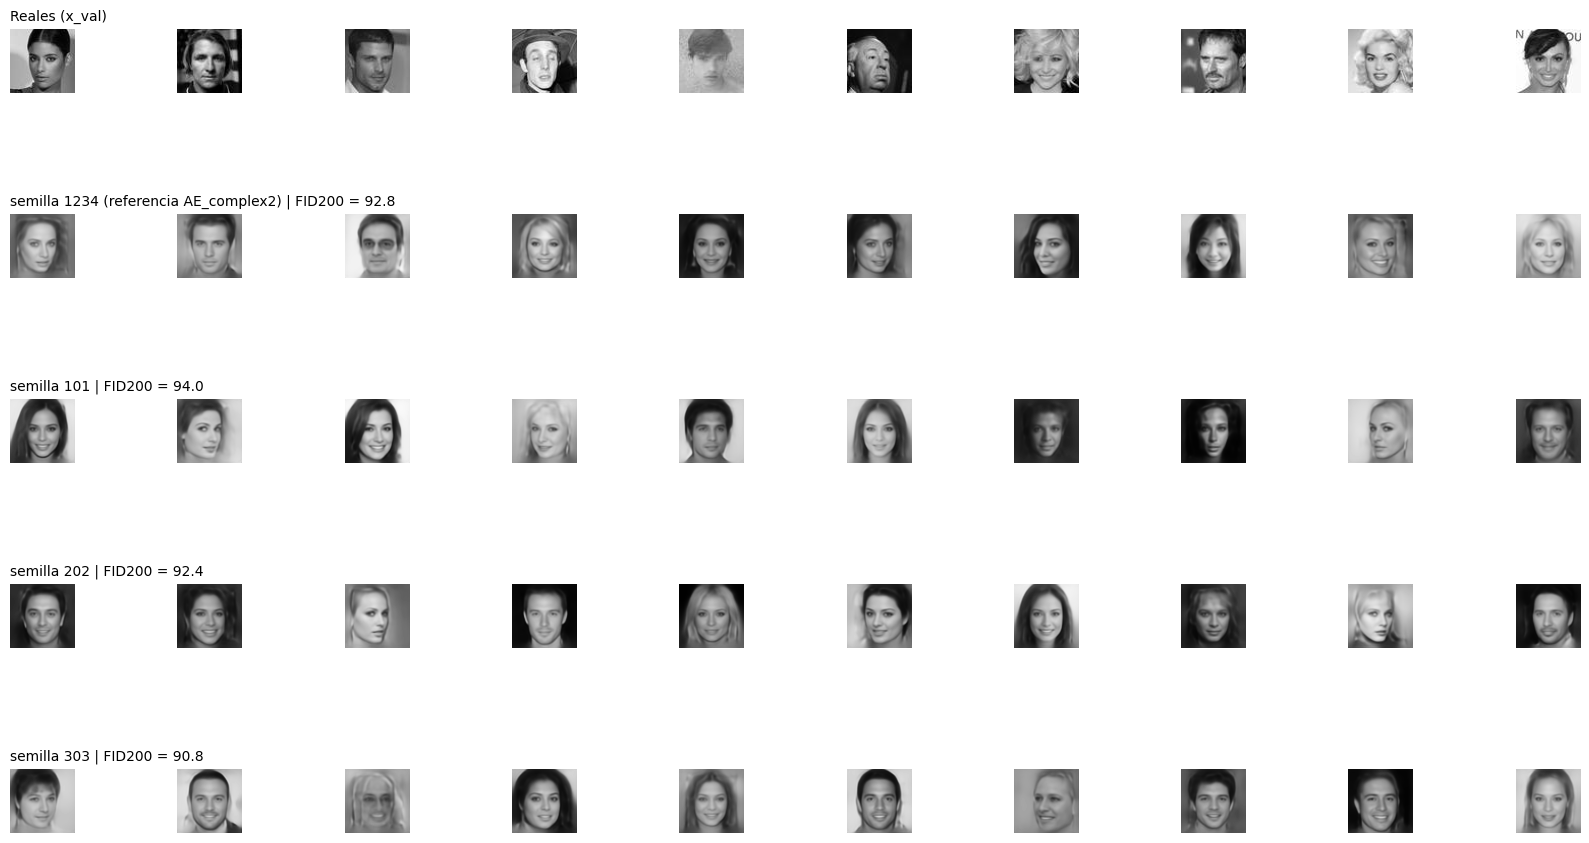

In [ ]:
seeds_to_show = [SAMPLE_SEED] + list(OVERFIT_SEEDS)
n_cols = 10
fig, axes = plt.subplots(len(seeds_to_show) + 1, n_cols, figsize=(1.6 * n_cols, 1.9 * (len(seeds_to_show) + 1)))
for c in range(n_cols):
    axes[0, c].imshow(x_val[c, ..., 0], cmap="gray", vmin=0, vmax=1)
axes[0, 0].set_title("Reales (x_val)", loc="left", fontsize=10)

for r, seed in enumerate(seeds_to_show, start=1):
    for c in range(n_cols):
        axes[r, c].imshow(images_by_seed[seed][c], cmap="gray", vmin=0, vmax=255)
    tag = " (referencia AE_complex2)" if seed == SAMPLE_SEED else ""
    axes[r, 0].set_title(f"semilla {seed}{tag} | FID200 = {fid_by_seed[seed]:.1f}", loc="left", fontsize=10)

for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.show()

---

## **7. Resultados**

En Kaggle:
- Semilla **101**: 87.3
- Semilla **202**: 83.0
- Semilla **303**: 85.0

Ni se parecen a los resultados locales, ni a los de referencia de AE_complex2.
Probablemente si probasemos `N` intentos tanto con este método como algunos GMM con varias semillas, encontraríamos una submission con un FID máximo para el Kaggle pero no tiene ningún sentido didáctico.

## Fusión de caras de personas fuera del dataset

Se cargan las dos fotos ya recortadas, se pasan a gris, se reescalan a 64x64 y se normalizan a `[0, 1]`. Después se codifican con el encoder y se guarda `z_mean` de cada una (`z_A` y `z_B`). También se reconstruyen para comprobar el resultado.

Se usa `z_mean` y no `z` porque `z` incluye ruido aleatorio y daría un código distinto cada vez. La reconstrucción sirve de control: si el VAE no reconstruye bien una foto, tampoco la fusionará bien.

In [ ]:
FOTO_A = "data_test/edgar.jpg"
FOTO_B = "data_test/guille.jpg"

def load_face(path):
    img = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    if img is None:
        raise FileNotFoundError(f"No se encuentra {path}")
    img = cv2.resize(img, (IMG_SIZE, IMG_SIZE), interpolation=cv2.INTER_AREA)
    return img.astype("float32")[..., None] / 255.0

face_a = load_face(FOTO_A)
face_b = load_face(FOTO_B)

zA = encoder_ae.predict(face_a[None], verbose=0)[0]
zB = encoder_ae.predict(face_b[None], verbose=0)[0]

rec_a = decode(zA[None])[0]
rec_b = decode(zB[None])[0]

fig, axes = plt.subplots(2, 2, figsize=(6, 6))
for ax, img, t in zip(axes.flat,
                      [face_a, rec_a, face_b, rec_b],
                      ["A (64x64)", "A reconstruida", "B (64x64)", "B reconstruida"]):
    ax.imshow(img[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(t)
    ax.axis("off")
plt.tight_layout()
plt.show()

## Interpolación entre las dos caras

Se calcula `z(α) = (1 − α)·z_A + α·z_B` para 9 valores de `α` entre 0 y 1 y se decodifica cada punto. La figura se guarda en `fusion_caras.png`.

Una interpolación lineal recorre el camino recto entre ambas caras en el espacio latente. En `α = 0` sale A, en `α = 1` sale B y en medio aparecen caras con rasgos de las dos. Ver varios pasos permite comprobar si la transición es suave, que es la señal de que el espacio latente está bien organizado.

In [ ]:
alphas = np.linspace(0, 1, 9)
z_interp = np.stack([(1 - a) * zA + a * zB for a in alphas]).astype(np.float32)
imgs_interp = decode(z_interp)

fig, axes = plt.subplots(1, len(alphas), figsize=(2 * len(alphas), 2.4))
for ax, img, a in zip(axes, imgs_interp, alphas):
    ax.imshow(img[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(f"α={a:.2f}", fontsize=9)
    ax.axis("off")
fig.suptitle("Fusión A → B en el espacio latente del AE", fontsize=12)
plt.tight_layout()
plt.savefig("fusion_ae_caras.png", dpi=200)
plt.show()

## Fusión con pesos distintos

Se generan tres mezclas (75% A / 25% B, 50% / 50% y 25% A / 75% B) y se muestran junto a las dos fotos originales.

In [ ]:
pesos = [0.25, 0.5, 0.75]
z_mix = np.stack([(1 - a) * zA + a * zB for a in pesos]).astype(np.float32)
imgs_mix = decode(z_mix)

todas = [face_a] + list(imgs_mix) + [face_b]
titulos = ["A original", "75% A / 25% B", "50% / 50%", "25% A / 75% B", "B original"]

fig, axes = plt.subplots(1, 5, figsize=(10, 2.4))
for ax, img, t in zip(axes, todas, titulos):
    ax.imshow(img[..., 0], cmap="gray", vmin=0, vmax=1)
    ax.set_title(t, fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.savefig("fusion_ae_pesos.png", dpi=200)
plt.show()